# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np
from pathlib import Path

# The exercise uses ../data; these alternatives also work when the notebook
# and the uploaded CSV are saved in the same directory.
possible_paths = [
    Path('../data/airbnb_london.csv'),
    Path('airbnb_london.csv'),
    Path('data/airbnb_london.csv'),
    Path('/mnt/data/airbnb_london.csv'),
]
data_path = next((p for p in possible_paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Put airbnb_london.csv beside the notebook or in ../data/.')

df = pd.read_csv(data_path)
print(f'Loaded: {len(df):,} listings from {data_path}')
print(df.describe().round(1))

Loaded: 2,500 listings from ../data/airbnb_london.csv
        price  minimum_nights  ...  availability_365  reviews_per_month
count  2500.0          2500.0  ...            2500.0             2500.0
mean    148.6            14.8  ...             183.7                2.0
std     110.9             8.4  ...             105.5                2.0
min      20.5             1.0  ...               0.0                0.0
25%      71.7             8.0  ...              92.0                0.6
50%     117.5            15.0  ...             182.0                1.4
75%     188.9            22.0  ...             277.0                2.8
max    1032.4            29.0  ...             364.0               15.2

[8 rows x 5 columns]


In [2]:
# Follow the exercise's starter code: exclude prices above the 95th percentile.
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95].copy()
price_outliers_removed = len(df) - len(df_cap)

print(f'95th percentile price: £{p95:,.2f}')
print(f'Listings retained: {len(df_cap):,}; above cutoff: {price_outliers_removed:,}')
print(df_cap.groupby('room_type')['price'].describe().round(1))

95th percentile price: £372.66
Listings retained: 2,375; above cutoff: 125
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

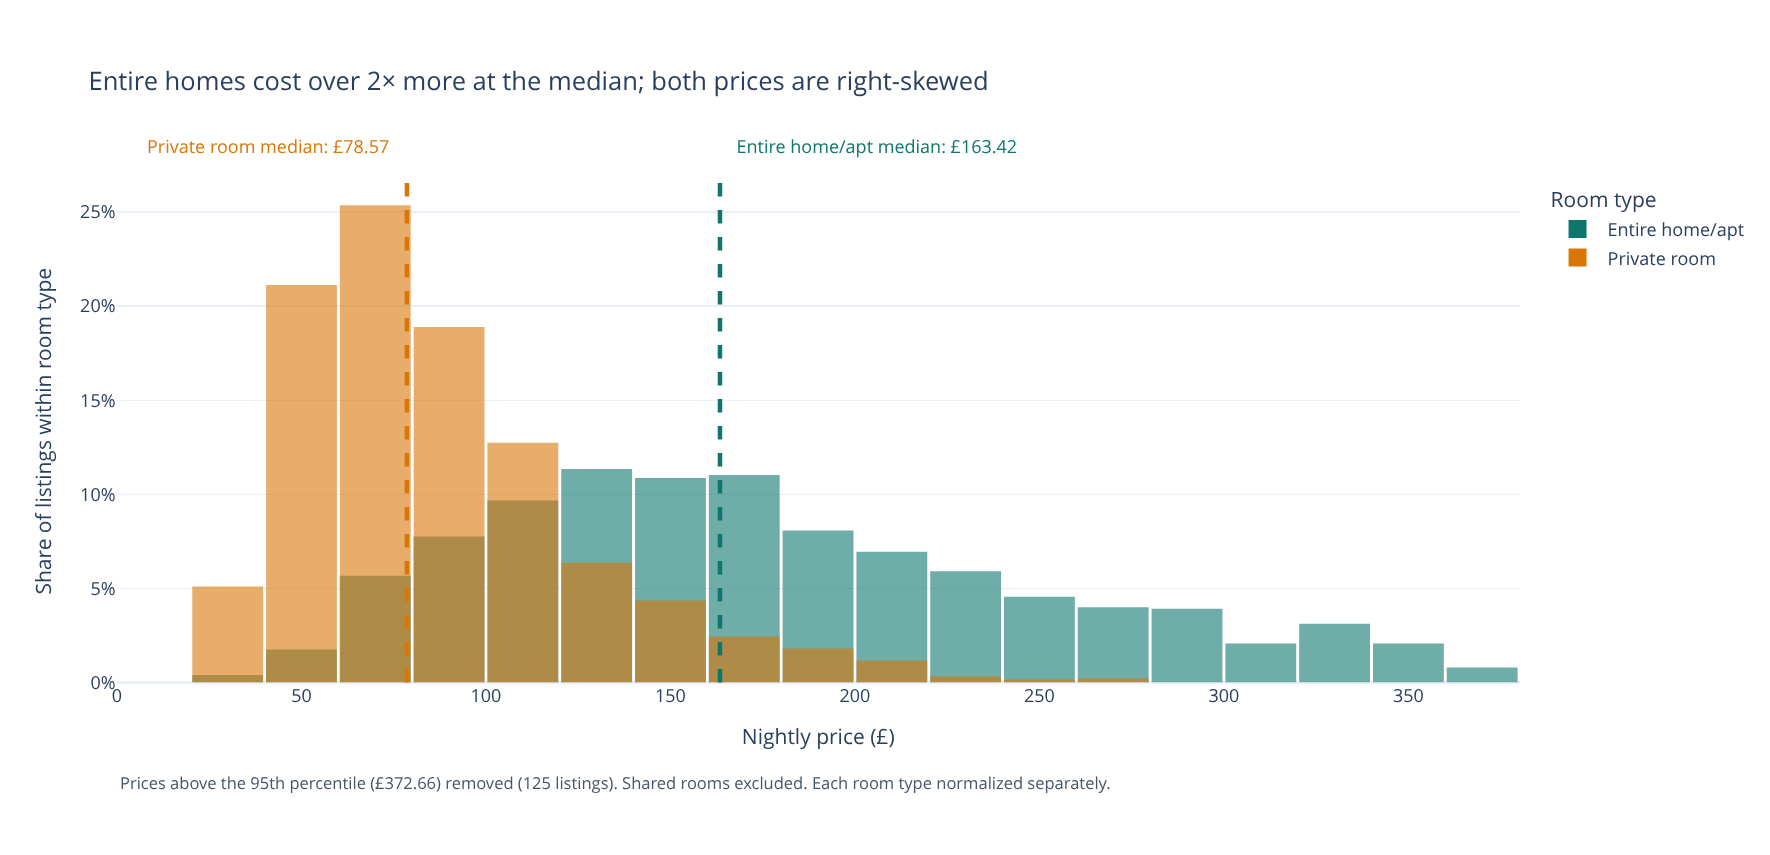

Medians (after the cutoff):
room_type
Entire home/apt    163.420
Private room        78.575
Entire home / private room median ratio: 2.08×


In [3]:
# Task 1 — Histogram: overlapping nightly prices by room type.
# Requirement: shared rooms excluded, barmode='overlay', opacity=0.6.
room_order = ['Entire home/apt', 'Private room']
room_colors = {
    'Entire home/apt': '#0F766E',  # teal identifies entire homes
    'Private room': '#D97706',     # amber identifies private rooms
}
price_data = df_cap[df_cap['room_type'].isin(room_order)].copy()
price_medians = price_data.groupby('room_type')['price'].median()

fig1 = px.histogram(
    price_data,
    x='price',
    color='room_type',
    color_discrete_map=room_colors,
    category_orders={'room_type': room_order},
    barmode='overlay',
    opacity=0.6,
    nbins=32,
    histnorm='probability',  # compare within-room-type shares, not raw sample sizes
    labels={'price': 'Nightly price (£)', 'room_type': 'Room type'},
    title='Entire homes cost over 2× more at the median; both prices are right-skewed',
)

# Requirement: two distinct, individually annotated median reference lines.
for room in room_order:
    value = price_medians.loc[room]
    fig1.add_vline(
        x=value,
        line_color=room_colors[room],
        line_dash='dash',
        line_width=3,
    )
    fig1.add_annotation(
        x=value,
        y=1.035,
        xref='x', yref='paper',
        text=f'{room} median: £{value:,.2f}',
        showarrow=False,
        xanchor='left' if room == 'Entire home/apt' else 'right',
        xshift=9 if room == 'Entire home/apt' else -9,
        yanchor='bottom',
        font=dict(size=12, color=room_colors[room]),
    )

fig1.update_layout(
    template='plotly_white',
    width=1180,
    height=570,
    margin=dict(t=120, b=115, l=78, r=35),
    bargap=0.04,
    legend_title_text='Room type',
    yaxis_title='Share of listings within room type',
)
fig1.update_yaxes(tickformat='.0%')
fig1.update_xaxes(range=[0, float(p95) * 1.02])
fig1.add_annotation(
    x=0, y=-0.23, xref='paper', yref='paper',
    text=(f'Prices above the 95th percentile (£{p95:,.2f}) removed '
          f'({price_outliers_removed} listings). Shared rooms excluded. '
          'Each room type normalized separately.'),
    xanchor='left', showarrow=False,
    font=dict(size=11, color='#475569'),
)
fig1.show()

print('Medians (after the cutoff):')
print(price_medians.reindex(room_order).round(3).to_string())
print(f'Entire home / private room median ratio: '
      f'{price_medians.loc["Entire home/apt"] / price_medians.loc["Private room"]:.2f}×')

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

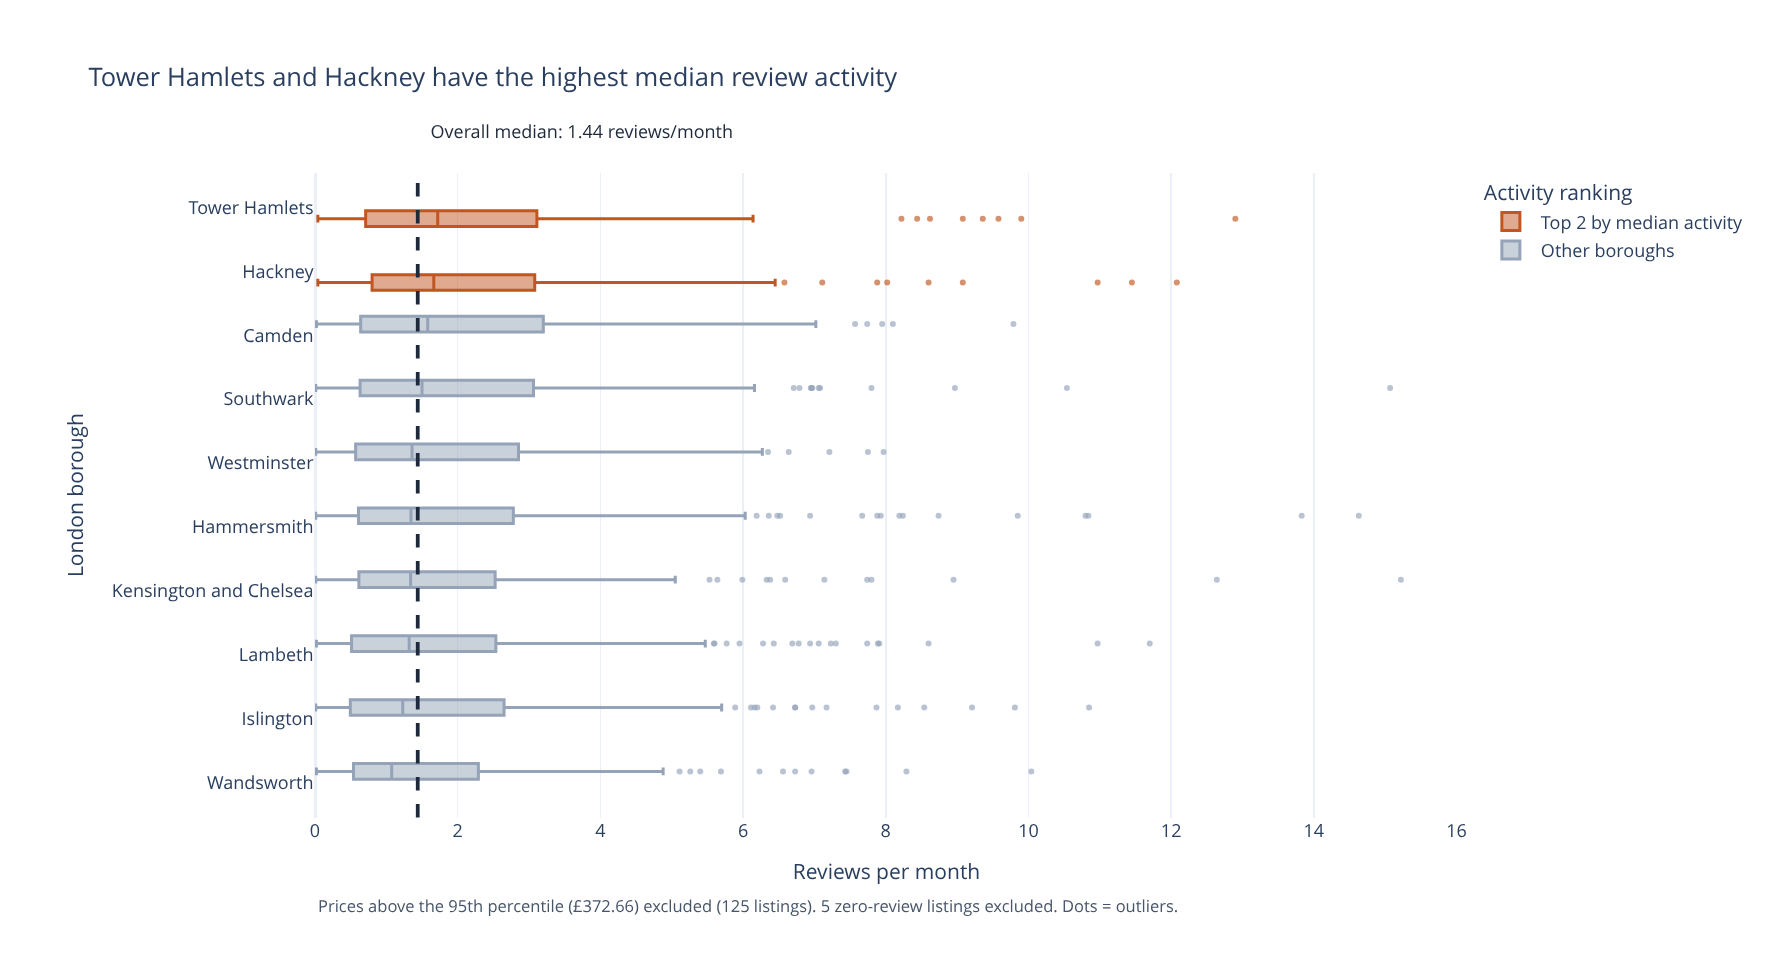

Borough median reviews/month (descending):
neighbourhood
Tower Hamlets             1.720
Hackney                   1.665
Camden                    1.580
Southwark                 1.500
Westminster               1.360
Hammersmith               1.345
Kensington and Chelsea    1.340
Lambeth                   1.320
Islington                 1.230
Wandsworth                1.075
Overall median: 1.44 reviews/month
Borough listings plotted: 2,370


In [4]:
# Task 2 — Horizontal borough box plots, ordered by median reviews/month.
# Exclude zero-review listings before finding medians or plotting.
activity_data = df_cap[df_cap['reviews_per_month'] > 0].copy()
zero_review_removed = (df_cap['reviews_per_month'] <= 0).sum()
borough_medians = (
    activity_data.groupby('neighbourhood')['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)
top_two = borough_medians.index[:2].tolist()
activity_data['highlight'] = np.where(
    activity_data['neighbourhood'].isin(top_two),
    'Top 2 by median activity',
    'Other boroughs',
)
activity_colors = {
    'Top 2 by median activity': '#C05621',
    'Other boroughs': '#94A3B8',
}
all_boroughs_median = activity_data['reviews_per_month'].median()

fig2 = px.box(
    activity_data,
    x='reviews_per_month',
    y='neighbourhood',
    color='highlight',
    orientation='h',
    points='outliers',  # requirement: show individual outlier dots
    color_discrete_map=activity_colors,
    category_orders={
        'neighbourhood': borough_medians.index[::-1].tolist(),
        'highlight': ['Top 2 by median activity', 'Other boroughs'],
    },
    labels={
        'reviews_per_month': 'Reviews per month',
        'neighbourhood': 'London borough',
        'highlight': 'Borough group',
    },
    title=f'{top_two[0]} and {top_two[1]} have the highest median review activity',
)
fig2.update_traces(boxpoints='outliers', marker=dict(size=4, opacity=0.65))
# Plotly plots the final category at the top, so reverse the descending ranking.
fig2.update_yaxes(
    categoryorder='array',
    categoryarray=borough_medians.index[::-1].tolist(),
)
# Requirement: reference line with a numeric annotation.
fig2.add_vline(
    x=all_boroughs_median,
    line_color='#1E293B',
    line_dash='dash',
    line_width=2.5,
)
fig2.add_annotation(
    x=all_boroughs_median, y=1.04,
    xref='x', yref='paper',
    text=f'Overall median: {all_boroughs_median:.2f} reviews/month',
    showarrow=False, xanchor='left', xshift=7,
    yanchor='bottom', font=dict(size=12, color='#1E293B'),
)
fig2.update_layout(
    template='plotly_white',
    width=1180,
    height=650,
    margin=dict(t=115, b=105, l=210, r=40),
    legend_title_text='Activity ranking',
    xaxis=dict(rangemode='tozero'),
)
fig2.add_annotation(
    x=0, y=-0.16, xref='paper', yref='paper',
    text=(f'Prices above the 95th percentile (£{p95:,.2f}) excluded '
          f'({price_outliers_removed} listings). '
          f'{zero_review_removed} zero-review listings excluded. Dots = outliers.'),
    xanchor='left', showarrow=False,
    font=dict(size=11, color='#475569'),
)
fig2.show()

print('Borough median reviews/month (descending):')
print(borough_medians.round(3).to_string())
print(f'Overall median: {all_boroughs_median:.2f} reviews/month')
print(f'Borough listings plotted: {len(activity_data):,}')

## Insights and interpretation

**Task 1 — Right-skewed price distributions:** After removing the top 5% of prices (nightly prices above **£372.66**), an **Entire home/apt** has a median nightly price of **£163.42**, versus **£78.575** for a **Private room**. Entire homes are **2.08×** as expensive at the median. Both distributions have longer tails towards higher prices. Shared rooms are excluded as the task requests.

**Task 2 — Activity concentrated most in Tower Hamlets and Hackney:** Among listings with positive monthly reviews and prices within the cutoff, **Tower Hamlets** leads (median **1.72** reviews/month), with **Hackney** second (**1.665** reviews/month). The overall activity median is **1.44** reviews/month. Boroughs are sorted by median with the highest at the top; orange marks the two top-ranked boroughs, grey the remainder, and individual dots show outliers.

**Cleaning and caveat:** The 95th-percentile filter removes **125** listings from the 2,500 observations; the activity chart additionally filters **5** listings with zero reviews/month. Reviews per month is a useful *proxy for listing activity*, not an exact measure of bookings or occupancy.